# TAM400: VPN or NonVPN Traffic Classification
## Balanced Random Forest experiment

**Student 1:** Shucayb AHmed Said | **Student 2:** Ayub Ali Barre | **Group:** 17

**Research question:** Can nine numerical flow measurements distinguish VPN from NonVPN traffic, and can tuning reduce the forest's training-validation gap?

Open this notebook in Google Colab and use **Runtime > Run all** on a CPU runtime. The complete experiment is here: raw-data download, cleaning, exploration, model training, cross-validation, tuning, test evaluation and final results. The search evaluates 200 reproducibly sampled settings plus three controls using five folds. This is a larger CPU experiment and can take several minutes. A GPU is not needed.

The included outputs come from a fresh local execution of this revised notebook. Running every cell in Colab recomputes all results. No saved model, separate notebook or external results file is loaded. Library versions are printed below.

The target is **NonVPN = 0** or **VPN = 1**. Each row is a network flow. This is an offline experiment, not a detector for the computer's current connection.

## 1. Import the libraries
These libraries are normally available in Colab. The first cell installs a library only if it is missing.

In [1]:
import importlib.util
import subprocess
import sys

packages = {"sklearn": "scikit-learn", "pandas": "pandas",
            "numpy": "numpy", "matplotlib": "matplotlib"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

from pathlib import Path
from io import StringIO
from urllib.request import urlretrieve
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, ParameterSampler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
from sklearn.base import clone
print("matplotlib:", __import__("matplotlib").__version__)

Python: 3.12.14
scikit-learn: 1.6.1
pandas: 2.2.3
NumPy: 2.1.3
matplotlib: 3.10.7


## 2. Download and inspect the raw dataset
We use the ISCXVPN2016 dataset described by the **Canadian Institute for Cybersecurity at the University of New Brunswick, Canada**. It contains labelled traffic recorded with and without a VPN. The original university description and paper explain how the data was collected.

- **Original dataset source:** https://www.unb.ca/cic/datasets/vpn.html
- **Research paper:** https://doi.org/10.5220/0005740704070414
- **Exact feature-file copy used here:** https://github.com/shafwanur/thd-ss25-ml-project/blob/b4488cf1022157a319d9ccdfa36f86cb940e2b80/data/15s.arff

Our code downloads this fixed public copy of the feature file for a 15-second flow timeout. Only the **raw data** is downloaded. The checksum checks that we have the expected copy each time. It does **not** verify that the copy is identical to the university archive. The official download route leads to a registration form. We have not independently compared our copy with that archive.

ARFF files have a header followed by comma-separated data rows. `class1` contains the original application labels.

In [2]:
url = "https://raw.githubusercontent.com/shafwanur/thd-ss25-ml-project/b4488cf1022157a319d9ccdfa36f86cb940e2b80/data/15s.arff"
expected_hash = "8b12e8c0cd49f56af28cdaa7c2aa7795ee24de0b1bedf638280e00404f7c1563"
data_file = Path("15s.arff")
if not data_file.exists():
    urlretrieve(url, data_file)
assert hashlib.sha256(data_file.read_bytes()).hexdigest() == expected_hash, "Unexpected dataset file"

# Read the ARFF column names and then its data rows.
lines = data_file.read_text().splitlines()
columns = [line.split()[1] for line in lines if line.upper().startswith("@ATTRIBUTE")]
start = next(i for i, line in enumerate(lines) if line.upper().startswith("@DATA")) + 1
df = pd.read_csv(StringIO("\n".join(lines[start:])), names=columns)
print("Raw rows and columns:", df.shape)
display(df.head())

Raw rows and columns: (18758, 24)


,duration,total_fiat,total_biat,min_fiat,min_biat,max_fiat,max_biat,mean_fiat,mean_biat,flowPktsPerSecond,flowBytesPerSecond,min_flowiat,max_flowiat,mean_flowiat,std_flowiat,min_active,mean_active,max_active,std_active,min_idle,mean_idle,max_idle,std_idle,class1
0,9368711,16,4,1564818,1549373,190205.285714,203290.456522,389822.391917,370323.719754,10.353612,4802.688438,4,1523088,97590.739583,267600.198443,1871488,1.983656e+06,2195089,1.832197e+05,1234883,1420565.0,1523088,161096.539275,CHAT
1,7340238,18,4,1567554,1527893,165686.977273,186914.846154,317267.548742,304370.651301,11.580006,4340.186245,4,1517774,87383.785714,221462.862028,1491627,3.572433e+06,5653239,2.942704e+06,1131498,1324636.0,1517774,273138.379008,CHAT
2,4644225,29,15,1270547,1079974,165865.178571,195302.130435,329473.126261,300492.588227,11.412022,4161.512416,15,1079974,89312.019231,217475.425246,1758922,1.758922e+06,1758922,0.000000e+00,1079974,1079974.0,1079974,0.000000,CHAT
3,4978735,19,8,2492050,2457286,239543.250000,276596.388889,612435.304238,628339.573544,8.034169,3918.666087,8,2441990,127659.871795,436959.716436,1710925,2.382905e+06,3054885,9.503232e+05,1346073,1894031.5,2441990,774930.342317,CHAT
4,11838189,19,10,3094089,3093543,243766.500000,295954.725000,599721.781709,625632.703972,7.602514,2802.540152,10,3042717,133013.359551,436129.639296,1747431,2.400446e+06,3240696,6.232744e+05,1394455,1983227.0,3042717,725987.829075,CHAT


## 3. Create the inputs and target, then clean the data
We select nine numerical measurements to keep the project small. `class1` is used only to create the target; including it in the inputs would reveal the answer.

Negative durations and traffic rates are invalid, so we replace them with missing values. We first keep one copy of identical input-and-label rows. If an input vector still occurs more than once, it has conflicting labels, so we remove both versions. These cleaning rules are specific to this dataset.

In [3]:
features = ["duration", "flowPktsPerSecond", "flowBytesPerSecond",
            "min_flowiat", "max_flowiat", "mean_flowiat", "std_flowiat",
            "mean_active", "mean_idle"]
X = df[features].copy()
y = df["class1"].str.strip().str.upper().str.startswith("VPN-").astype(int).rename("vpn")

negative_cells = int((X < 0).sum().sum())
X[X < 0] = np.nan
clean = pd.concat([X, y], axis=1)
clean = clean.drop_duplicates()  # Keep one row when both inputs and label are identical.
clean = clean.drop_duplicates(subset=features, keep=False)  # Remove conflicting labels.
removed_rows = len(df) - len(clean)
X, y = clean[features], clean["vpn"]

print("Invalid negative cells replaced with missing values:", negative_cells)
print("Duplicate or conflicting rows removed:", removed_rows)
print("Clean rows:", len(clean))
print("Number of input features:", X.shape[1])

Invalid negative cells replaced with missing values: 1240
Duplicate or conflicting rows removed: 779
Clean rows: 17979
Number of input features: 9


## 4. Split the data and fix the selection rule
Keep the same stratified 80/20 split and seed 42: 14,383 training flows and 3,596 test flows. Five shuffled stratified folds, also with seed 42, are used only within the training partition.

**Desired ranges:** about 92–93% full-training accuracy, 0.91–0.92 validation VPN F1 and 91–92% test accuracy. These are aspirations, not filters, stopping rules or values to force. Accuracy and F1 are different metrics; compare like with like when measuring a gap.

**Rule fixed before this search:** find the largest mean validation VPN F1. Retain candidates within its fold standard deviation divided by the square root of five. Among those candidates choose the smallest nonnegative fold-training minus validation F1 gap. Ties favour higher validation F1, then the fixed candidate order. A negative gap receives a gap of zero for this ordering. This one-standard-error allowance is a practical heuristic, not a confidence interval or proof of equal performance.

The grid, sample count and seeds below are fixed before execution. Full-training accuracy and the desired ranges do not choose the model. After selection, fit the chosen configuration on all training data, freeze it and evaluate the test set once. Reuse those predictions throughout the notebook. The test partition has already been viewed in earlier revisions, so this remains a reused development test, not a new independent evaluation. No test score is used to guide this expanded search.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
print("Training flows:", len(X_train))
print("Test flows:", len(X_test))
print("Training class counts (0 = NonVPN, 1 = VPN):")
print(y_train.value_counts().sort_index())

Training flows: 14383
Test flows: 3596
Training class counts (0 = NonVPN, 1 = VPN):
vpn
0    6927
1    7456
Name: count, dtype: int64


## 5. Explore the training data
Duration means the elapsed time between the first and last packet in a flow. **ISCXFlowMeter stores duration in microseconds.** Its original implementation documents the unit and divides duration by 1,000,000 when calculating packets per second:
https://github.com/ahlashkari/ISCXFlowMeter/blob/f3287486f114350b0b79dcfcf1050bc6a85190cf/src/main/java/iscx/cs/unb/ca/ifm/data/BasicFlow.java#L168-L172

For the histogram, divide by **1,000,000 to show seconds**. The full-range plot keeps the long flows. The second panel zooms to 0–15 seconds for readability and states how many flows are outside that view. It does not remove them from training. The file's 15-second timeout name is not a guarantee that every recorded duration is at most 15 seconds.

Many flows end quickly, while fewer last much longer. This produces a right-skewed distribution. The plots describe the observed distribution, not the applications responsible for it.

The Pearson table measures **linear** association with VPN=1. Low correlation does not mean that a feature is useless. Random Forest can learn nonlinear relationships and interactions between features. Keep all nine inputs. Only the graph uses seconds; the model inputs remain in their original units.

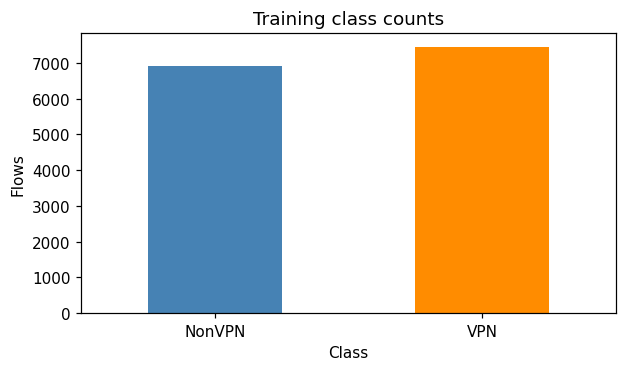

Training duration in seconds:


count    14383.000
mean        10.178
std         14.860
min          0.000
25%          0.692
50%         11.850
75%         14.960
95%         14.999
max        601.405
Name: duration, dtype: float64

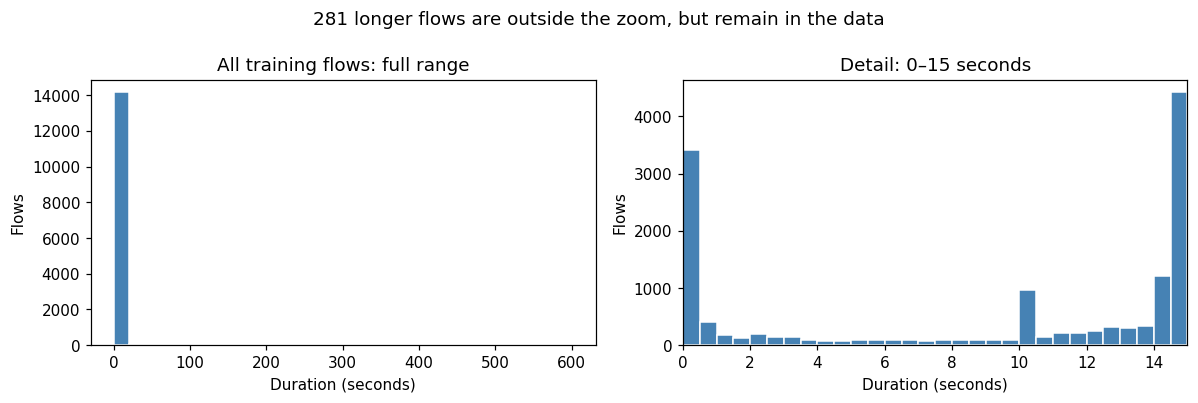

,Feature,Pearson correlation with VPN
0,mean_flowiat,0.0532
1,min_flowiat,0.0378
2,std_flowiat,0.0050
3,flowPktsPerSecond,0.0007
4,mean_active,-0.0077
5,max_flowiat,-0.0133
6,mean_idle,-0.0151
7,flowBytesPerSecond,-0.0347
8,duration,-0.0670


In [5]:
fig, ax = plt.subplots(figsize=(5.8, 3.5), num="class_counts")
y_train.value_counts().sort_index().plot.bar(ax=ax, color=["steelblue", "darkorange"])
ax.set(xticklabels=["NonVPN", "VPN"], xlabel="Class", ylabel="Flows", title="Training class counts")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

duration_seconds = X_train["duration"].dropna() / 1_000_000
duration_summary = duration_seconds.describe(percentiles=[0.25, 0.50, 0.75, 0.95])
print("Training duration in seconds:")
display(duration_summary.round(3))
outside_zoom = int((duration_seconds > 15).sum())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.7), num="duration_histogram")
axes[0].hist(duration_seconds, bins=30, color="steelblue", edgecolor="white")
axes[0].set(title="All training flows: full range", xlabel="Duration (seconds)", ylabel="Flows")
axes[1].hist(duration_seconds, bins=np.linspace(0, 15, 31), color="steelblue", edgecolor="white")
axes[1].set(title="Detail: 0–15 seconds", xlabel="Duration (seconds)", ylabel="Flows", xlim=(0, 15))
fig.suptitle(f"{outside_zoom:,} longer flows are outside the zoom, but remain in the data")
plt.tight_layout()
plt.show()

training_data = X_train.copy()
training_data["vpn"] = y_train
correlation_table = training_data.corr(numeric_only=True)["vpn"].drop("vpn").sort_values(ascending=False)
display(correlation_table.rename_axis("Feature").reset_index(name="Pearson correlation with VPN").round(4))

## 6. Train the baseline
We use `DummyClassifier` as our reference model. We call it the **baseline**. Our `strategy="most_frequent"` setting makes it predict the most common training class for every flow. This lets us check whether the other models improve on a simple prediction rule.

Every pipeline fits its median imputer on training data only. Keeping preprocessing inside the pipeline also protects the validation folds.

In [6]:
baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", DummyClassifier(strategy="most_frequent"))
])
baseline.fit(X_train, y_train)
print("Baseline trained on", len(X_train), "flows.")

Baseline trained on 14383 flows.


## 7. Train SGDClassifier
`SGDClassifier` learns a linear decision boundary. We add `StandardScaler` because the numerical inputs have very different ranges. The scaler is fitted inside the pipeline.

In [7]:
sgd_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", SGDClassifier(random_state=42))
])
sgd_model.fit(X_train, y_train)
print("SGDClassifier trained on", len(X_train), "flows.")

SGDClassifier trained on 14383 flows.


## 8. Train the default Random Forest
The default forest is the reference for the tuning experiment. It uses 100 trees, unlimited depth, at least two samples to split a node and one sample per leaf. `max_features="sqrt"` considers three of our nine features at each split. These flexible trees can fit the training set very closely.

We keep its default settings and `random_state=42`. The classifier does not need standard scaling. The median imputer is fitted within the pipeline.

In [8]:
forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(random_state=42))
])
forest_model.fit(X_train, y_train)
print("Random Forest trained on", len(X_train), "flows.")
print("Number of trees:", forest_model.named_steps["model"].n_estimators)

Random Forest trained on 14383 flows.
Number of trees: 100


## 9. Check full-training accuracy and F1
These predictions use data the fitted models have already seen. Report both accuracy and VPN F1. A high training score alone is not enough to diagnose overfitting. Next, compare training-fold F1 with validation-fold F1, using the same metric.

In [9]:
pipelines = {"Baseline": baseline, "SGDClassifier": sgd_model, "Default RF": forest_model}
training_rows = []
for name, model in pipelines.items():
    prediction = model.predict(X_train)
    training_rows.append({"Model": name,
                          "Training accuracy": accuracy_score(y_train, prediction),
                          "Training VPN F1": f1_score(y_train, prediction, zero_division=0)})
training_results = pd.DataFrame(training_rows)
display(training_results.round(4))

,Model,Training accuracy,Training VPN F1
0,Baseline,0.5184,0.6828
1,SGDClassifier,0.5893,0.6420
2,Default RF,0.9999,0.9999


## 10. Compare the initial models using training folds
Use five shuffled stratified folds within the training partition. Each fit uses four folds and predicts the fifth, with median imputation fitted inside its training fold.

VPN F1 is the primary selection metric. Record training and validation accuracy separately so we never subtract F1 from accuracy. The fold standard deviation measures variation between folds, not an independent confidence interval. No test rows enter these calculations. Scores from the earlier three-fold run are not directly substituted into this five-fold comparison.

,Model,CV training F1,CV training accuracy,CV F1 mean,CV F1 std,CV accuracy
2,Default RF,1.0000,1.0000,0.8976,0.0064,0.8932
0,Baseline,0.6828,0.5184,0.6828,0.0001,0.5184
1,SGDClassifier,0.6455,0.5914,0.6456,0.0074,0.5915


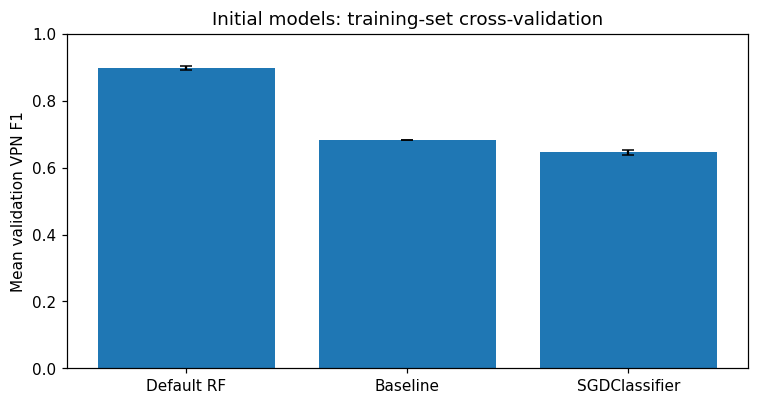

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"f1": "f1", "accuracy": "accuracy"}
cv_scores = {}
comparison_rows = []
for name, model in pipelines.items():
    scores = cross_validate(model, X_train, y_train, scoring=scoring, cv=cv,
                            return_train_score=True, n_jobs=2)
    cv_scores[name] = scores
    comparison_rows.append({
        "Model": name,
        "CV training F1": scores["train_f1"].mean(),
        "CV training accuracy": scores["train_accuracy"].mean(),
        "CV F1 mean": scores["test_f1"].mean(),
        "CV F1 std": scores["test_f1"].std(),
        "CV accuracy": scores["test_accuracy"].mean()})
comparison = pd.DataFrame(comparison_rows).sort_values("CV F1 mean", ascending=False)
display(comparison.round(4))
fig, ax = plt.subplots(figsize=(7, 3.8), num="initial_comparison")
ax.bar(comparison["Model"], comparison["CV F1 mean"], yerr=comparison["CV F1 std"], capsize=4)
ax.set(ylim=(0, 1), ylabel="Mean validation VPN F1", title="Initial models: training-set cross-validation")
plt.tight_layout()
plt.show()

## 11. Search for a better balance using training data only
We reproducibly sample 200 unique configurations from the space below using seed 42. Three controls are added: the original 100-tree default, the previous 100-tree tuned configuration, and a 200-tree default. GridSearchCV evaluates this fixed candidate list using five folds, giving 1,015 search fits. All candidates use bootstrap sampling, seed 42, no class weighting and the ordinary prediction threshold. The classes are fairly balanced.

| Parameter | Sampled values | Purpose |
|---|---|---|
| `max_depth` | 6, 8, 10, 12, 16, 20, None | Limit tree depth |
| `min_samples_split` | 2, 10, 20 | Avoid splits based on too few rows |
| `min_samples_leaf` | 1, 2, 4, 8, 16 | Control how small a final leaf can be |
| `max_features` | sqrt, 6, 1.0 | Consider three, six or all nine inputs per split |
| `max_samples` | 0.2, 0.35, 0.5, 0.75, None | Draw this fraction of training rows per tree, with replacement; None draws the full row count |
| `criterion` | gini, entropy | Two ways to measure improvement from a split |
| `n_estimators` | 200 | Average more trees; the historical controls retain 100 |

Sampling this space is bounded and reproducible; it does not test every possible forest. The imputer remains inside the pipeline. `max_samples` changes each tree's bootstrap draw, not the train/test partition.

Apply the rule stated in section 4: find peak mean validation F1, keep near-best candidates, then prefer the smallest training–validation F1 gap. The search table includes both F1 and accuracy. A scatter plot shows the predictive-performance versus gap trade-off. The desired training range is only a diagnostic, and cannot make a weak model eligible.

After selection, the leaf-size curve varies only that parameter while holding the selected settings fixed. It is diagnostic and cannot change the selected model. All fits in this section exclude the test partition. The final selection is printed before test evaluation.

Candidates evaluated: 203
Ten highest validation-F1 settings:


,max_depth,min_samples_split,min_samples_leaf,max_features,max_samples,criterion,n_estimators,CV training accuracy,CV accuracy,CV training F1,CV F1 mean,CV F1 std,CV F1 gap
0,None,2,1,sqrt,None,gini,100,1.0000,0.8932,1.0000,0.8976,0.0064,0.1024
2,None,2,1,sqrt,None,gini,200,1.0000,0.8929,1.0000,0.8975,0.0056,0.1025
44,20,2,1,sqrt,0.75,entropy,200,0.9960,0.8920,0.9961,0.8970,0.0049,0.0991
185,20,10,1,6,None,entropy,200,0.9796,0.8917,0.9804,0.8969,0.0053,0.0835
16,20,2,2,sqrt,None,gini,200,0.9889,0.8913,0.9893,0.8963,0.0056,0.0930
74,16,2,1,sqrt,0.75,gini,200,0.9848,0.8905,0.9855,0.8960,0.0054,0.0895
43,None,10,1,sqrt,None,gini,200,0.9811,0.8906,0.9817,0.8956,0.0062,0.0862
141,16,2,2,sqrt,None,entropy,200,0.9740,0.8898,0.9752,0.8952,0.0047,0.0800
175,16,2,2,6,0.75,gini,200,0.9699,0.8892,0.9712,0.8949,0.0046,0.0764
6,20,2,2,6,0.5,gini,200,0.9632,0.8885,0.9646,0.8939,0.0044,0.0707


Peak CV F1: 0.8976
One-standard-error allowance: 0.0029
Eligibility threshold: 0.8947
Eligible settings: 9
Selected parameters: {'model__criterion': 'gini', 'model__max_depth': 16, 'model__max_features': 6, 'model__max_samples': 0.75, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 200}
Candidates with mean fold-training accuracy between 92% and 93%: 17


,max_depth,min_samples_split,min_samples_leaf,max_features,max_samples,criterion,n_estimators,CV training accuracy,CV accuracy,CV training F1,CV F1 mean,CV F1 std,CV F1 gap
81,20,20,1,6,0.5,entropy,200,0.9299,0.8826,0.9331,0.8885,0.0078,0.0446
61,16,2,4,6,0.35,entropy,200,0.9236,0.8808,0.9273,0.8872,0.0064,0.0402
197,20,10,8,6,0.75,gini,200,0.9281,0.8807,0.9313,0.8869,0.0062,0.0444
129,12,10,4,6,0.75,entropy,200,0.9255,0.8797,0.9294,0.8866,0.0059,0.0427
89,None,20,8,sqrt,0.75,entropy,200,0.9261,0.8803,0.9294,0.8865,0.0052,0.0429


Candidates reaching mean validation VPN F1 of at least 0.91: 0


,Training accuracy,Training VPN F1,CV training F1,CV training accuracy,CV F1 mean,CV F1 std,CV accuracy,CV F1 gap,CV accuracy gap
Model,,,,,,,,,
Default RF,0.9999,0.9999,1.0000,1.0000,0.8976,0.0064,0.8932,0.1024,0.1068
Tuned RF,0.9673,0.9688,0.9712,0.9699,0.8949,0.0046,0.8892,0.0764,0.0806


MODEL SELECTED BEFORE TEST EVALUATION: Tuned RF
Selection uses validation F1 and comparable F1 gaps, not target accuracy ranges.


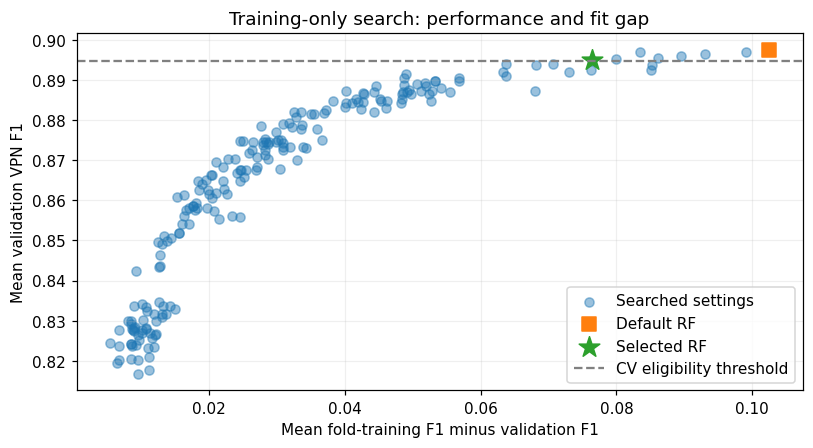

,param_model__min_samples_leaf,mean_train_f1,std_train_f1,mean_test_f1,std_test_f1
0,1,0.9858,0.0014,0.8961,0.0045
1,2,0.9712,0.0019,0.8949,0.0046
2,4,0.9513,0.0012,0.8918,0.0060
3,8,0.9282,0.0005,0.8859,0.0053
4,16,0.9045,0.0020,0.8748,0.0069


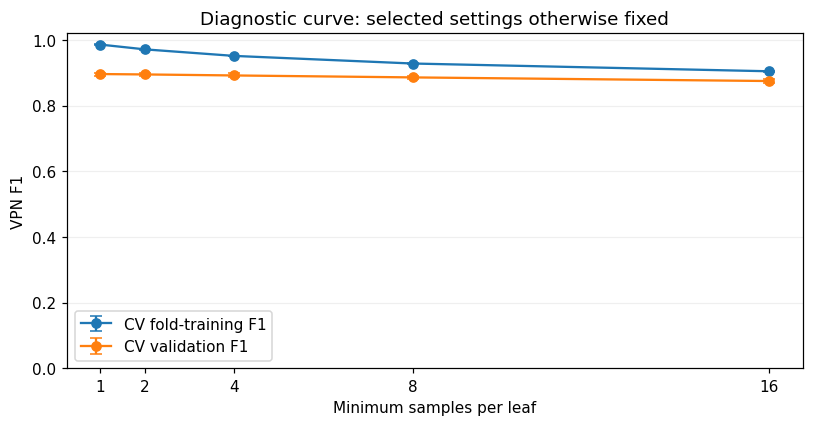

In [11]:
# These candidate values and the selection rule are fixed before fitting.
grid = {
    "model__max_depth": [6, 8, 10, 12, 16, 20, None],
    "model__min_samples_split": [2, 10, 20],
    "model__min_samples_leaf": [1, 2, 4, 8, 16],
    "model__max_features": ["sqrt", 6, 1.0],
    "model__max_samples": [0.2, 0.35, 0.5, 0.75, None],
    "model__criterion": ["gini", "entropy"],
    "model__n_estimators": [200]
}
control = {"model__max_depth": None, "model__min_samples_split": 2,
           "model__min_samples_leaf": 1, "model__max_features": "sqrt",
           "model__max_samples": None, "model__criterion": "gini",
           "model__n_estimators": 100}
candidates = [control,
              {**control, "model__max_depth": 20, "model__min_samples_split": 10},
              {**control, "model__n_estimators": 200}]
for candidate in ParameterSampler(grid, n_iter=200, random_state=42):
    if candidate not in candidates:
        candidates.append(candidate)
candidate_grid = [{key: [value] for key, value in candidate.items()} for candidate in candidates]
search = GridSearchCV(forest_model, candidate_grid, scoring=scoring, refit=False, cv=cv,
                      return_train_score=True, n_jobs=2, error_score="raise")
search.fit(X_train, y_train)
tuning = pd.DataFrame(search.cv_results_)
peak_index = tuning["mean_test_f1"].idxmax()
peak_cv_f1 = float(tuning.loc[peak_index, "mean_test_f1"])
selection_allowance = float(tuning.loc[peak_index, "std_test_f1"] / np.sqrt(cv.get_n_splits()))
selection_threshold = peak_cv_f1 - selection_allowance
tuning["F1 gap"] = tuning["mean_train_f1"] - tuning["mean_test_f1"]
tuning["selection gap"] = tuning["F1 gap"].clip(lower=0)
eligible = tuning.loc[tuning["mean_test_f1"] >= selection_threshold]
tuned_index = eligible.sort_values(["selection gap", "mean_test_f1"], ascending=[True, False], kind="stable").index[0]
selected_params = tuning.loc[tuned_index, "params"]
tuned_model = clone(forest_model).set_params(**selected_params)
tuned_model.fit(X_train, y_train)

parameter_columns = ["param_" + name for name in grid]
tuning_table = tuning[parameter_columns + ["mean_train_accuracy", "mean_test_accuracy", "mean_train_f1", "mean_test_f1", "std_test_f1", "F1 gap"]].copy()
tuning_table.columns = [name.replace("model__", "") for name in grid] + ["CV training accuracy", "CV accuracy", "CV training F1", "CV F1 mean", "CV F1 std", "CV F1 gap"]
print("Candidates evaluated:", len(tuning))
print("Ten highest validation-F1 settings:")
display(tuning_table.sort_values("CV F1 mean", ascending=False).head(10).round(4))
print("Peak CV F1:", round(peak_cv_f1, 4))
print("One-standard-error allowance:", round(selection_allowance, 4))
print("Eligibility threshold:", round(selection_threshold, 4))
print("Eligible settings:", len(eligible))
print("Selected parameters:", selected_params)

# This diagnostic does not influence selection. Fold-training accuracy is
# not the same as fitting a model on the whole training partition.
near_training_target = tuning_table.loc[tuning_table["CV training accuracy"].between(0.92, 0.93)]
print("Candidates with mean fold-training accuracy between 92% and 93%:", len(near_training_target))
display(near_training_target.sort_values("CV F1 mean", ascending=False).head(5).round(4))
print("Candidates reaching mean validation VPN F1 of at least 0.91:", int((tuning["mean_test_f1"] >= 0.91).sum()))

default_cv = comparison.set_index("Model").loc["Default RF"]
rf_models = {"Default RF": forest_model, "Tuned RF": tuned_model}
rf_rows = []
for name, model in rf_models.items():
    train_prediction = model.predict(X_train)
    row = tuning.loc[tuned_index] if name == "Tuned RF" else tuning.loc[0]
    rf_rows.append({"Model": name,
        "Training accuracy": accuracy_score(y_train, train_prediction),
        "Training VPN F1": f1_score(y_train, train_prediction),
        "CV training F1": row["mean_train_f1"],
        "CV training accuracy": row["mean_train_accuracy"],
        "CV F1 mean": row["mean_test_f1"], "CV F1 std": row["std_test_f1"],
        "CV accuracy": row["mean_test_accuracy"]})
rf_comparison = pd.DataFrame(rf_rows).set_index("Model")
rf_comparison["CV F1 gap"] = rf_comparison["CV training F1"] - rf_comparison["CV F1 mean"]
rf_comparison["CV accuracy gap"] = rf_comparison["CV training accuracy"] - rf_comparison["CV accuracy"]
display(rf_comparison.round(4))
best_name = "Tuned RF"
final_model = rf_models[best_name]
best_cv_f1 = float(rf_comparison.loc[best_name, "CV F1 mean"])
print("MODEL SELECTED BEFORE TEST EVALUATION:", best_name)
print("Selection uses validation F1 and comparable F1 gaps, not target accuracy ranges.")

fig, ax = plt.subplots(figsize=(7.5, 4.2), num="search_tradeoff")
ax.scatter(tuning["F1 gap"], tuning["mean_test_f1"], alpha=0.45, label="Searched settings")
ax.scatter(rf_comparison.loc["Default RF", "CV F1 gap"], default_cv["CV F1 mean"], marker="s", s=90, label="Default RF")
ax.scatter(tuning.loc[tuned_index, "F1 gap"], best_cv_f1, marker="*", s=200, label="Selected RF")
ax.axhline(selection_threshold, color="gray", linestyle="--", label="CV eligibility threshold")
ax.set(xlabel="Mean fold-training F1 minus validation F1", ylabel="Mean validation VPN F1", title="Training-only search: performance and fit gap")
ax.legend(loc="best")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Diagnostic only: all other parameters stay at their selected values.
curve_search = GridSearchCV(clone(tuned_model), {"model__min_samples_leaf": [1, 2, 4, 8, 16]},
                          scoring=scoring, refit=False, cv=cv, return_train_score=True, n_jobs=2)
curve_search.fit(X_train, y_train)
curve_results = pd.DataFrame(curve_search.cv_results_)
validation_curve_table = curve_results[["param_model__min_samples_leaf", "mean_train_f1", "std_train_f1", "mean_test_f1", "std_test_f1"]]
display(validation_curve_table.round(4))
leaf_sizes = validation_curve_table["param_model__min_samples_leaf"].astype(int)
fig, ax = plt.subplots(figsize=(7.5, 4), num="validation_curve")
ax.errorbar(leaf_sizes, validation_curve_table["mean_train_f1"], yerr=validation_curve_table["std_train_f1"], marker="o", capsize=4, label="CV fold-training F1")
ax.errorbar(leaf_sizes, validation_curve_table["mean_test_f1"], yerr=validation_curve_table["std_test_f1"], marker="o", capsize=4, label="CV validation F1")
ax.set(xlabel="Minimum samples per leaf", ylabel="VPN F1", xticks=[1, 2, 4, 8, 16], ylim=(0, 1.02), title="Diagnostic curve: selected settings otherwise fixed")
ax.legend(loc="lower left")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 12. Evaluate the two frozen forests once on the test set
The choice above is complete. Predict once with each forest, save those predictions in memory and reuse them below. Also evaluate the reference model for context. No test score is sent back to GridSearchCV or used to alter model selection.

Accuracy is the fraction of all correct predictions. VPN precision is the fraction of VPN predictions that are correct. VPN recall is the fraction of actual VPN flows found. VPN F1 combines precision and recall. ROC-AUC measures how well scores rank VPN above NonVPN flows.

Model,Default RF,Tuned RF
Training accuracy,0.9999,0.9673
Training VPN F1,0.9999,0.9688
CV training F1,1.0000,0.9712
CV training accuracy,1.0000,0.9699
CV F1 mean,0.8976,0.8949
CV F1 std,0.0064,0.0046
CV accuracy,0.8932,0.8892
CV F1 gap,0.1024,0.0764
CV accuracy gap,0.1068,0.0806
Test accuracy,0.9066,0.9024


Reference model test results:


,Test accuracy,VPN precision,VPN recall,VPN F1,ROC-AUC
Model,,,,,
Baseline,0.5184,0.5184,1.0,0.6828,0.5


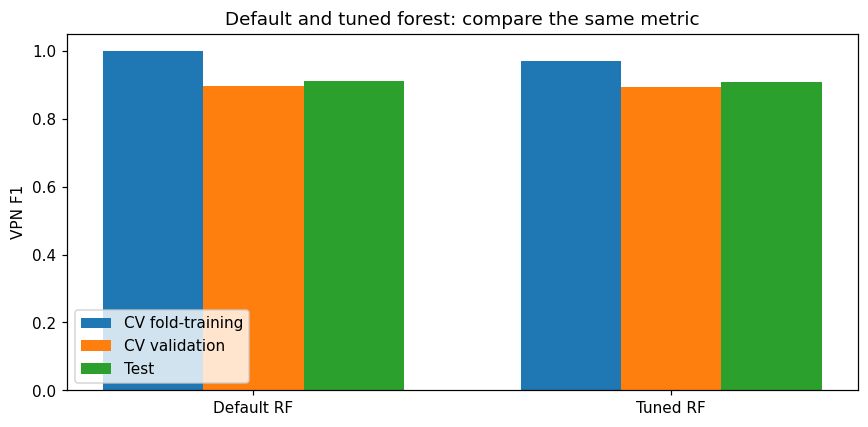

In [12]:
test_rows = []
test_predictions = {}
test_scores = {}
for name, model in {**rf_models, "Baseline": baseline}.items():
    prediction = model.predict(X_test)
    scores = model.predict_proba(X_test)[:, 1]
    test_predictions[name] = prediction
    test_scores[name] = scores
    test_rows.append({"Model": name,
                      "Test accuracy": accuracy_score(y_test, prediction),
                      "VPN precision": precision_score(y_test, prediction, zero_division=0),
                      "VPN recall": recall_score(y_test, prediction, zero_division=0),
                      "VPN F1": f1_score(y_test, prediction, zero_division=0),
                      "ROC-AUC": roc_auc_score(y_test, scores)})
results = pd.DataFrame(test_rows).set_index("Model")
final_comparison = rf_comparison.join(results)
final_comparison["Accuracy gap"] = final_comparison["Training accuracy"] - final_comparison["Test accuracy"]
display(final_comparison.T.round(4))
print("Reference model test results:")
display(results.loc[["Baseline"]].round(4))

fig, ax = plt.subplots(figsize=(8, 4), num="generalization_comparison")
x = np.arange(2)
width = 0.24
for offset, (column, label) in zip([-1, 0, 1], [("CV training F1", "CV fold-training"), ("CV F1 mean", "CV validation"), ("VPN F1", "Test")]):
    ax.bar(x + offset * width, final_comparison[column], width, label=label)
ax.set(xticks=x, xticklabels=final_comparison.index, ylabel="VPN F1", ylim=(0, 1.05), title="Default and tuned forest: compare the same metric")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

## 13. Compare both confusion matrices
Use the predictions saved in section 12. Rows show actual classes and columns show predicted classes. A false VPN alarm is NonVPN predicted as VPN. A missed VPN flow is VPN predicted as NonVPN.

Default RF | False VPN alarms: 189 | Missed VPN flows: 147
Tuned RF | False VPN alarms: 214 | Missed VPN flows: 137


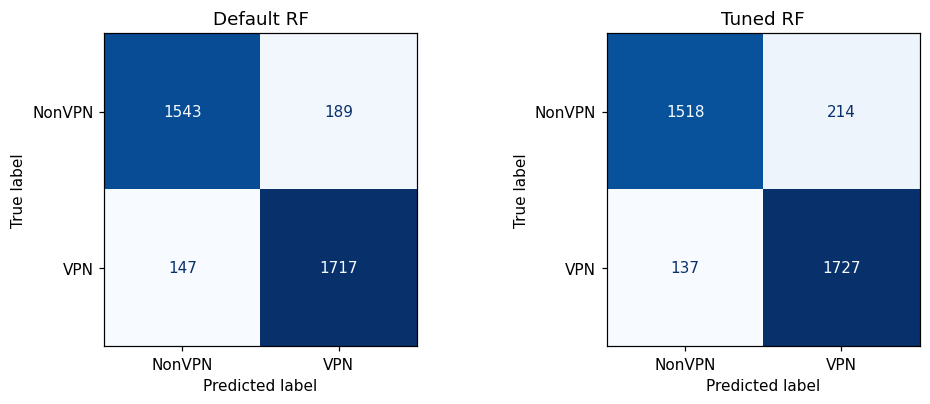

In [13]:
confusion_matrices = {}
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), num="confusion_matrices")
for ax, name in zip(axes, rf_models):
    matrix = confusion_matrix(y_test, test_predictions[name], labels=[0, 1])
    confusion_matrices[name] = matrix
    ConfusionMatrixDisplay(matrix, display_labels=["NonVPN", "VPN"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    print(name, "| False VPN alarms:", matrix[0, 1], "| Missed VPN flows:", matrix[1, 0])
plt.tight_layout()
plt.show()
final_prediction = test_predictions[best_name]

## 14. Compare example predictions with the true labels
These examples come from the test set. They demonstrate the predictions made by the model trained above; they do not inspect the current internet connection.

In [14]:
predictions = pd.DataFrame({
    "Source row": X_test.index,
    "Actual": np.where(y_test == 1, "VPN", "NonVPN"),
    "Predicted": np.where(final_prediction == 1, "VPN", "NonVPN")
})
display(predictions.head(10))

,Source row,Actual,Predicted
0,15291,VPN,NonVPN
1,4257,NonVPN,VPN
2,1260,NonVPN,NonVPN
3,2990,NonVPN,NonVPN
4,18400,NonVPN,NonVPN
5,8769,VPN,VPN
6,8271,VPN,VPN
7,9953,VPN,VPN
8,5218,NonVPN,NonVPN
9,886,NonVPN,VPN


## 15. Final comparison and interpretation from this run
These values are calculated from this run. The model name comes from the selection made before test evaluation. Lower training performance is only useful if validation performance remains strong. Compare the default and tuned models using F1 across training and validation, and accuracy across full training and test.

In [15]:
print("FINAL MODEL:", best_name)
print("Chosen before this run’s test evaluation using the CV-only near-best/gap rule.")
print("Selected parameters:", {name: final_model.named_steps["model"].get_params()[name] for name in ["n_estimators", "max_depth", "min_samples_split", "min_samples_leaf", "max_features", "max_samples", "criterion"]})
display(final_comparison.T.round(4))
default = final_comparison.loc["Default RF"]
tuned = final_comparison.loc["Tuned RF"]
gap_reduction = default["CV F1 gap"] - tuned["CV F1 gap"]
accuracy_gap_reduction = default["Accuracy gap"] - tuned["Accuracy gap"]
print(f"Default to tuned CV F1 change: {tuned['CV F1 mean'] - default['CV F1 mean']:+.4f}")
print(f"Reduction in fold-training/validation F1 gap: {gap_reduction * 100:.2f} percentage points")
print(f"Reduction in full-training/test accuracy gap: {accuracy_gap_reduction * 100:.2f} percentage points")
if gap_reduction > 0 and tuned["CV F1 mean"] >= selection_threshold:
    print("Tuning reduced the training-validation F1 gap while keeping validation F1 within the predefined CV allowance.")
    print("This supports reduced overfitting in this experiment, not its elimination. Report any small validation-score decrease as a trade-off.")
else:
    print("This run does not meet the stated gap-reduction and near-best validation conditions. Report this outcome honestly.")
print("A fresh independent traffic capture is still needed to confirm generalization.")
target_check = pd.DataFrame([
    {"Metric": "Full-training accuracy", "Desired range": "92–93%", "Measured": tuned["Training accuracy"], "Within range": 0.92 <= tuned["Training accuracy"] <= 0.93},
    {"Metric": "Mean validation VPN F1", "Desired range": "0.91–0.92", "Measured": tuned["CV F1 mean"], "Within range": 0.91 <= tuned["CV F1 mean"] <= 0.92},
    {"Metric": "Test accuracy", "Desired range": "91–92%", "Measured": tuned["Test accuracy"], "Within range": 0.91 <= tuned["Test accuracy"] <= 0.92}
])
display(target_check)
print("These target checks are descriptive only. They do not trigger further tuning.")
if peak_cv_f1 < 0.91:
    print("No configuration in this bounded search reached 0.91 mean validation VPN F1.")
    print("This does not prove that every possible Random Forest configuration would fail.")

FINAL MODEL: Tuned RF
Chosen before this run’s test evaluation using the CV-only near-best/gap rule.
Selected parameters: {'n_estimators': 200, 'max_depth': 16, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 6, 'max_samples': 0.75, 'criterion': 'gini'}


Model,Default RF,Tuned RF
Training accuracy,0.9999,0.9673
Training VPN F1,0.9999,0.9688
CV training F1,1.0000,0.9712
CV training accuracy,1.0000,0.9699
CV F1 mean,0.8976,0.8949
CV F1 std,0.0064,0.0046
CV accuracy,0.8932,0.8892
CV F1 gap,0.1024,0.0764
CV accuracy gap,0.1068,0.0806
Test accuracy,0.9066,0.9024


Default to tuned CV F1 change: -0.0027
Reduction in fold-training/validation F1 gap: 2.61 percentage points
Reduction in full-training/test accuracy gap: 2.84 percentage points
Tuning reduced the training-validation F1 gap while keeping validation F1 within the predefined CV allowance.
This supports reduced overfitting in this experiment, not its elimination. Report any small validation-score decrease as a trade-off.
A fresh independent traffic capture is still needed to confirm generalization.


,Metric,Desired range,Measured,Within range
0,Full-training accuracy,92–93%,0.967323,False
1,Mean validation VPN F1,0.91–0.92,0.894857,False
2,Test accuracy,91–92%,0.902392,False


These target checks are descriptive only. They do not trigger further tuning.
No configuration in this bounded search reached 0.91 mean validation VPN F1.
This does not prove that every possible Random Forest configuration would fail.


## 16. Interpretation and limitations
Use the measured comparison above to decide whether tuning helped. The validation curve shows the trade-off between fitting the training folds and predicting their held-out validation folds. We do not manually lower any training score. A reduction in training accuracy by itself would not prove improvement.

- Model selection uses the fixed CV-only near-best/gap rule, not test accuracy. The highest and selected CV scores are selection scores because the same folds informed the search and rule.
- The test partition was examined in previous project versions. This expanded search fixes its candidate space, sampling seed, five CV folds and selection rule before fitting, and freezes its selection before the one final test evaluation. This is still a reused development test, not independent confirmation.
- Removing contradictory input vectors excludes some difficult observations. Results apply to this cleaned dataset.
- Session identifiers are unavailable, so related flows may occur in both partitions.
- The public data copy has not been independently compared with the original archive. The traffic is historical.
- Evaluate new traffic captures, separated by session or capture, before claiming performance in a new environment.

The requested performance ranges are aspirations. We report any shortfall, and do not change the data split, labels, features or prediction threshold to chase them. This bounded search cannot rule out every other possible forest.

Save this notebook with its outputs so the complete experiment can be inspected in one file.

## 17. References and AI acknowledgment
1. G. Draper-Gil et al., *Characterization of Encrypted and VPN Traffic using Time-related Features*, ICISSP 2016, pp. 407–414. https://doi.org/10.5220/0005740704070414
2. Official ISCXVPN2016 dataset: https://www.unb.ca/cic/datasets/vpn.html
3. Exact feature-file copy: https://github.com/shafwanur/thd-ss25-ml-project/blob/b4488cf1022157a319d9ccdfa36f86cb940e2b80/data/15s.arff
4. Duration unit in the original ISCXFlowMeter implementation: https://github.com/ahlashkari/ISCXFlowMeter/blob/f3287486f114350b0b79dcfcf1050bc6a85190cf/src/main/java/iscx/cs/unb/ca/ifm/data/BasicFlow.java#L168-L172
5. Random Forest: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
6. GridSearchCV: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
7. Project repository: https://github.com/SAS2005/VPN-NonVPN-Classification-project

OpenAI Codex helped with explanations, source research, code generation and debugging, running the experiment locally, figures and drafting. The saved outputs in this revised notebook are from that local execution. We are responsible for reviewing, understanding and explaining the submitted work.

**Shucayb's contribution:** [complete with actual work]  
**Ayub's contribution:** [complete with actual work]